# 01. TIỀN XỬ LÝ DỮ LIỆU & BẢO VỆ DỮ LIỆU CÁ NHÂN 
**Thành viên phụ trách:** Thành viên 2 (Data Preparation) 
**Mục tiêu:**
- Khám phá cấu trúc, phát hiện lỗi dữ liệu khuyết thiếu và trùng lặp.
- Áp dụng chuẩn mực đạo đức nghề nghiệp IT: Loại bỏ thông tin định danh cá nhân (PII).
- Chuẩn hóa các trường thời gian và xuất tệp dữ liệu sạch sẵn sàng nạp cho AI Agent.

In [2]:
import os
import pandas as pd
import numpy as np

# Thiết lập đường dẫn tương đối từ notebooks/ sang data/
RAW_DATA_PATH = os.path.join('..', 'data', 'raw', 'Superstore.csv')
PROCESSED_DATA_PATH = os.path.join('..', 'data', 'processed', 'ecommerce_cleaned_for_agent.csv')

# Đảm bảo thư mục lưu dữ liệu sạch đã tồn tại
os.makedirs(os.path.dirname(PROCESSED_DATA_PATH), exist_ok=True)

# Đọc file dữ liệu gốc
df = pd.read_csv(RAW_DATA_PATH, encoding='latin1')
print(f"Kích thước ban đầu: {df.shape[0]} dòng, {df.shape[1]} cột")
df.head(3)

Kích thước ban đầu: 9994 dòng, 21 cột


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2013-152156,09-11-2013,12-11-2013,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2013-138688,13-06-2013,17-06-2013,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


## 1. Data Understanding (Kiểm tra cấu trúc và kiểu dữ liệu)
Đánh giá kiểu dữ liệu, các trường khuyết thiếu (missing values) và số dòng trùng lặp.

In [3]:
# Kiểm tra kiểu dữ liệu và số lượng non-null
df.info()

# Kiểm tra dòng trùng lặp hoàn toàn
duplicate_count = df.duplicated().sum()
print(f"\nSố lượng dòng trùng lặp hoàn toàn: {duplicate_count}")

# Kiểm tra dữ liệu khuyết thiếu trên từng cột
missing_info = df.isnull().sum()
print("\nSố lượng giá trị khuyết thiếu:")
print(missing_info[missing_info > 0] if missing_info.sum() > 0 else "Không có giá trị khuyết thiếu (Missing values = 0)")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

## 2. Đạo đức nghề nghiệp: Ẩn danh hóa thông tin PII & Làm sạch dữ liệu
- **Bảo mật quyền riêng tư:** Xóa bỏ trường `Customer Name` nhằm đảm bảo dữ liệu bàn giao cho AI Agent không lưu trữ thông tin định danh người dùng cá nhân.
- **Loại bỏ cột nhiễu context:** Xóa trường `Row ID` vì chỉ mang tính thứ tự dòng kỹ thuật, không có giá trị phân tích kinh doanh.
- **Xử lý trùng lặp:** Loại bỏ các dòng duplicate để không làm lệch số liệu thống kê.
- **Chuẩn hóa thời gian:** Ép kiểu trường `Order Date` và `Ship Date` sang định dạng `datetime` chuẩn.

In [4]:
# 1. Ẩn danh PII và xóa cột kỹ thuật không cần thiết
cols_to_drop = ['Customer Name', 'Row ID']
df_cleaned = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

# 2. Xóa các bản ghi trùng lặp
df_cleaned = df_cleaned.drop_duplicates()

# 3. Chuẩn hóa trường thời gian
df_cleaned['Order Date'] = pd.to_datetime(df_cleaned['Order Date'], errors='coerce')
df_cleaned['Ship Date'] = pd.to_datetime(df_cleaned['Ship Date'], errors='coerce')

# 4. Làm tròn các cột định lượng tiền tệ về 2 chữ số thập phân
df_cleaned['Sales'] = df_cleaned['Sales'].round(2)
df_cleaned['Profit'] = df_cleaned['Profit'].round(2)
df_cleaned['Discount'] = df_cleaned['Discount'].round(2)

print(f"Kích thước sau làm sạch: {df_cleaned.shape[0]} dòng, {df_cleaned.shape[1]} cột")
print("Danh sách cột dữ liệu sạch:\n", list(df_cleaned.columns))

Kích thước sau làm sạch: 9993 dòng, 19 cột
Danh sách cột dữ liệu sạch:
 ['Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


## 3. Xuất tệp dữ liệu đã làm sạch cho AI Agent
Lưu bộ dữ liệu vào `data/processed/ecommerce_cleaned_for_agent.csv`

In [5]:
df_cleaned.to_csv(PROCESSED_DATA_PATH, index=False, encoding='utf-8')
print(f"Đã lưu thành công bộ dữ liệu sạch tại: {PROCESSED_DATA_PATH}")

Đã lưu thành công bộ dữ liệu sạch tại: ..\data\processed\ecommerce_cleaned_for_agent.csv


# 02. PHÂN TÍCH KHÁM PHÁ DỮ LIỆU (EDA) & TRỰC QUAN HÓA
**Mục tiêu:**
- Thống kê mô tả các chỉ số định lượng kinh doanh (Doanh thu, Lợi nhuận, Tỷ suất lợi nhuận).
- Trực quan hóa mối quan hệ giữa các biến: Ngành hàng, Xu hướng thời gian, Phân khúc khách hàng.
- Rút ra quy luật kinh doanh và xác định các kịch bản truy vấn cho AI Agent.

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình giao diện biểu đồ
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

# Nạp dữ liệu sạch từ data/processed/
DATA_PATH = os.path.join('..', 'data', 'processed', 'ecommerce_cleaned_for_agent.csv')
df = pd.read_csv(DATA_PATH)
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

print(f"Nạp dữ liệu thành công: {df.shape[0]} dòng và {df.shape[1]} cột")

Nạp dữ liệu thành công: 9993 dòng và 19 cột


## 1. Thống kê mô tả tổng quan (Business Overview)
Tính toán các chỉ số kinh doanh cốt lõi làm mốc đối chứng (Ground Truth) khi kiểm thử phản hồi của AI Agent.

In [7]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
avg_sales = df['Sales'].mean()
profit_margin = (total_profit / total_sales) * 100

print(f"• Tổng doanh thu toàn hệ thống : ${total_sales:,.2f}")
print(f"• Tổng lợi nhuận ròng          : ${total_profit:,.2f}")
print(f"• Giá trị đơn hàng trung bình   : ${avg_sales:,.2f}")
print(f"• Tỷ suất lợi nhuận (Margin)    : {profit_margin:.2f}%")
print(f"• Tổng số đơn hàng thực tế      : {df['Order ID'].nunique():,} đơn")

# Bảng mô tả phân phối các cột định lượng
df[['Sales', 'Quantity', 'Discount', 'Profit']].describe().round(2)

• Tổng doanh thu toàn hệ thống : $2,296,919.28
• Tổng lợi nhuận ròng          : $286,408.60
• Giá trị đơn hàng trung bình   : $229.85
• Tỷ suất lợi nhuận (Margin)    : 12.47%
• Tổng số đơn hàng thực tế      : 5,009 đơn


,Sales,Quantity,Discount,Profit
count,9993.00,9993.00,9993.00,9993.00
mean,229.85,3.79,0.16,28.66
std,623.28,2.23,0.21,234.27
min,0.44,1.00,0.00,-6599.98
25%,17.28,2.00,0.00,1.73
50%,54.48,3.00,0.20,8.67
75%,209.94,5.00,0.20,29.36
max,22638.48,14.00,0.80,8399.98


## 2. Phân tích doanh thu & lợi nhuận theo danh mục sản phẩm (Category)
So sánh hiệu quả tài chính giữa 3 ngành hàng lớn: *Furniture*, *Office Supplies*, và *Technology*

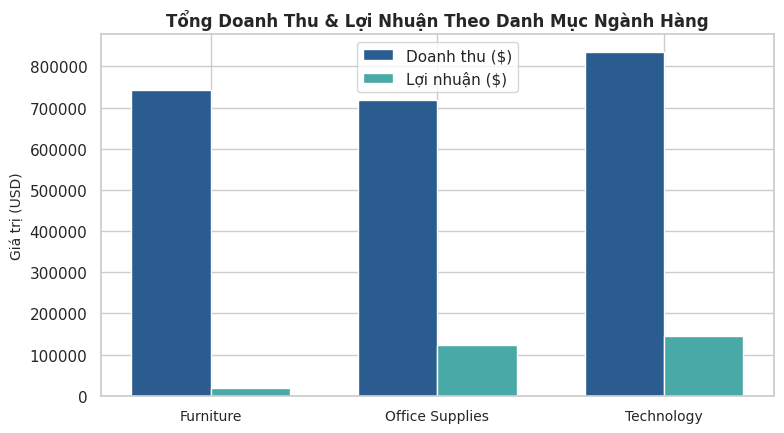

In [8]:
cat_summary = df.groupby('Category')[['Sales', 'Profit']].sum().reset_index()

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(cat_summary['Category']))
width = 0.35

ax1.bar(x - width/2, cat_summary['Sales'], width, label='Doanh thu ($)', color='#2b5c8f')
ax1.bar(x + width/2, cat_summary['Profit'], width, label='Lợi nhuận ($)', color='#48a9a6')

ax1.set_title('Tổng Doanh Thu & Lợi Nhuận Theo Danh Mục Ngành Hàng', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(cat_summary['Category'], fontsize=10)
ax1.set_ylabel('Giá trị (USD)', fontsize=10)
ax1.legend()
plt.tight_layout()
plt.show()

## 3. Phân tích xu hướng biến động theo thời gian (Monthly Sales Trend)
Xem xét chu kỳ mua sắm theo tháng để nhận diện tính chu kỳ và các mùa cao điểm bán hàng

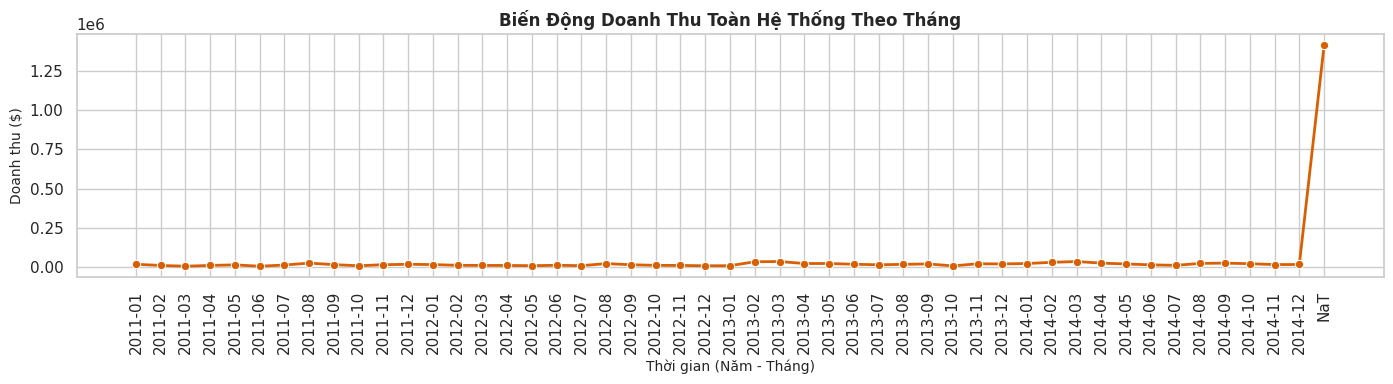

In [9]:
df['YearMonth'] = df['Order Date'].dt.to_period('M').astype(str)
monthly_data = df.groupby('YearMonth')['Sales'].sum().reset_index()

plt.figure(figsize=(14, 4))
sns.lineplot(data=monthly_data, x='YearMonth', y='Sales', marker='o', color='#d95f02', linewidth=2)
plt.title('Biến Động Doanh Thu Toàn Hệ Thống Theo Tháng', fontsize=12, fontweight='bold')
plt.xlabel('Thời gian (Năm - Tháng)', fontsize=10)
plt.ylabel('Doanh thu ($)', fontsize=10)
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

## 4. Đánh giá rủi ro lợi nhuận theo danh mục con (Sub-Category)
Nhận diện các mặt hàng đang bị thua lỗ (Lợi nhuận âm) do chi phí cao hoặc tỷ lệ chiết khấu giảm giá quá lớn

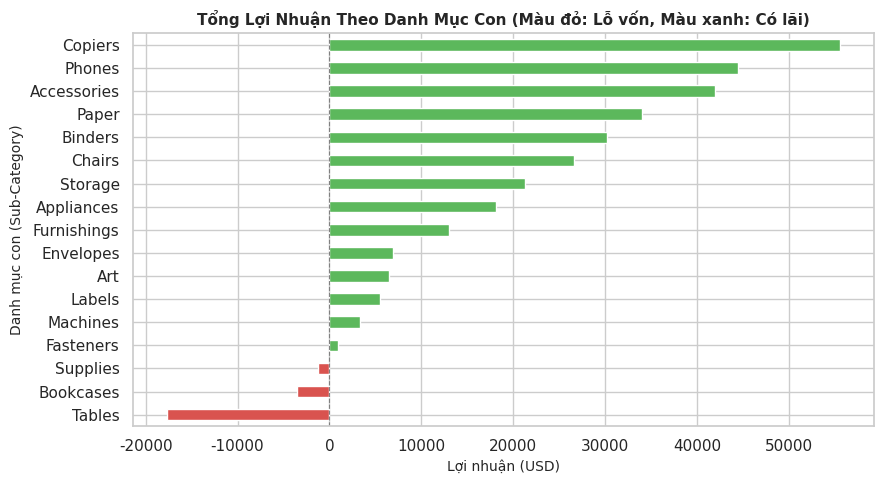

In [10]:
subcat_profit = df.groupby('Sub-Category')['Profit'].sum().sort_values()

plt.figure(figsize=(9, 5))
colors = ['#d9534f' if val < 0 else '#5cb85c' for val in subcat_profit.values]
subcat_profit.plot(kind='barh', color=colors)

plt.title('Tổng Lợi Nhuận Theo Danh Mục Con (Màu đỏ: Lỗ vốn, Màu xanh: Có lãi)', fontsize=11, fontweight='bold')
plt.xlabel('Lợi nhuận (USD)', fontsize=10)
plt.ylabel('Danh mục con (Sub-Category)', fontsize=10)
plt.axvline(0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

## 5. Tổng kết & Đề xuất kịch bản truy vấn cho AI Agent
Từ kết quả EDA, hệ thống AI Agent cần hỗ trợ các nhóm tác vụ sau:
1. **Lọc dữ liệu:** Tra cứu các đơn hàng lỗ vốn trong ngành hàng cụ thể (ví dụ: `Tables` hoặc `Bookcases`).
2. **Thống kê:** Tính tổng doanh thu theo khoảng thời gian và phân khúc khách hàng.
3. **Trực quan hóa:** Gọi tool vẽ biểu đồ đường xu hướng doanh thu theo tháng khi người dùng yêu cầu.